In [1]:
#import random
import torch as tc
import numpy as np
import qutip as qt
import sys
sys.path.insert(0, '../../PopsCtrl/')
import function as my
import matplotlib.pyplot as plt
import random
from tqdm import tqdm
import torch.nn as nn


device = tc.device('cuda' if tc.cuda.is_available() else 'cpu')
print(f"Executando no dispositivo: {device}")

if device.type == 'cpu':
  num_threads = 10
  tc.set_num_threads(num_threads)
  tc.set_num_interop_threads(num_threads)

Executando no dispositivo: cpu


In [2]:
def Fieldx(t):
    return ( 1.5* np.sin(2.0 * t) - 0.3*np.cos(3* t - 0.5) + 0.4*np.sin(5.0 * t)
        )*np.sin(np.pi*t/tfinal)**2
def Fieldy(t):
    # return np.zeros(len(t))
    return ( 0.5* np.sin(5.0 * t) - 0.8*np.cos(1* t - 0.5) + 1.4*np.sin(3.0 * t)
        )*np.sin(np.pi*t/tfinal)**2

def Fieldz(t):
    # return np.ones(len(t))
    return ( -0.5* np.sin(0.2 * t) - 1.8*np.cos(5* t - 0.5) - .4*np.sin(3.0 * t)
        )*np.sin(np.pi*t/tfinal)**2


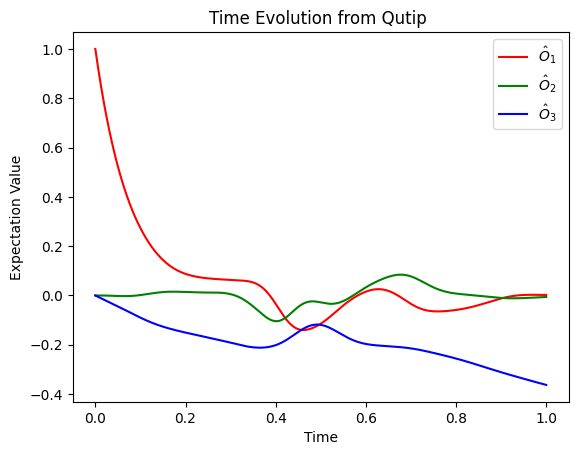

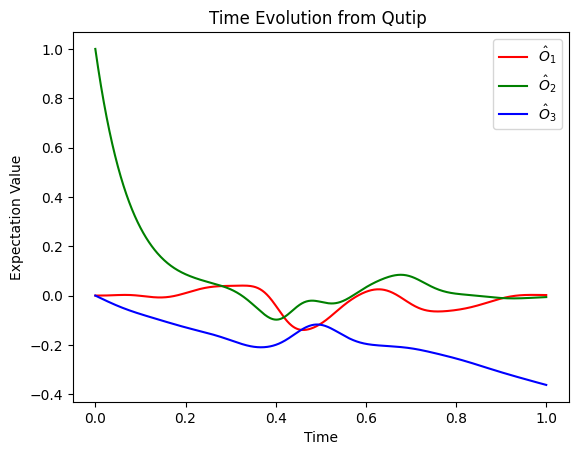

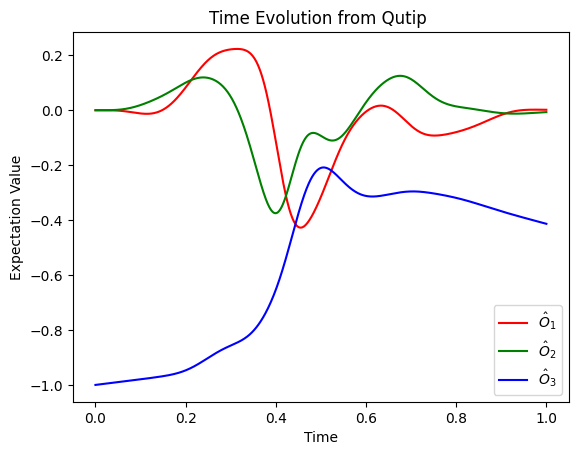

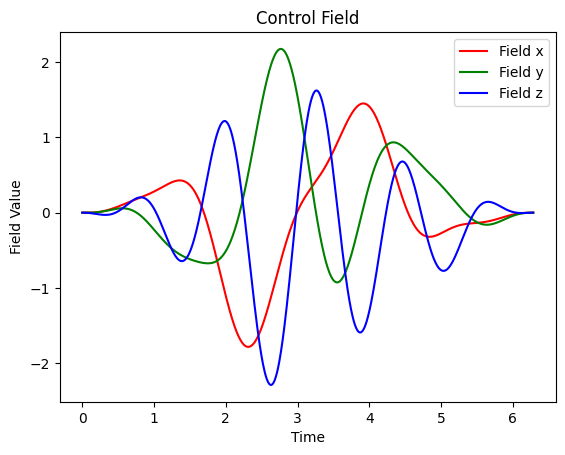

In [ ]:

def data_qubit(dissipation,tlist,O_op,fieldx,fieldy,fieldz,psi0,device):
    # Operadores de Pauli para cada qubit
    X,Y,Z = qt.sigmax(),qt.sigmay(),qt.sigmaz()
    
    H  = [[0.5*X,fieldx(tlist)],[0.5*Y,fieldy(tlist)],[0.5*Z,fieldz(tlist)]]

    # Hamiltonian Lindbladian
    c_ops = [np.sqrt(dissipation[0])*qt.sigmam(),
             np.sqrt(dissipation[1])*qt.sigmaz(),
             np.sqrt(dissipation[2])*qt.sigmam().dag()]
             
    # Solução da equação de Schrödinger
    options = {'nsteps': 100000, 'atol': 1e-14, 'rtol': 1e-14}
    result  = qt.mesolve(H, psi0, tlist, c_ops=c_ops, e_ops=O_op,options=options)

    expect  = tc.tensor( np.array( result.expect),device = device).transpose(0, 1)
    return expect
O_op =[ qt.sigmax(),qt.sigmay(),qt.sigmaz()]
tfinal      =2*np.pi
N           = 800
tlist = np.linspace(0.0, tfinal, N)
SEED=15
# Definindo a seed
np.random.seed(SEED)
tc.manual_seed(SEED) 
random.seed(SEED)

# Js          = np.random.uniform(-1,1,15)
# dissipation = np.random.rand(4)
#Js          = [random.uniform(-1,1) for _ in range(3)]
dissipation = [0.1*random.uniform(0,1) for _ in range(3)]
# Estado inicial (cada qubit na superposição de |0> e |1>)
# |+> = (|0> + |1>)/sqrt(2)
theta1  = np.pi/4
phi1    = 0.0 #np.pi/3
ket_plus1 = (np.cos(theta1)*qt.basis(2, 0)+np.sin(theta1)*np.exp(1j*phi1)*qt.basis(2, 1))
psi1 = ket_plus1
valor_esperado_data1  = data_qubit(dissipation,tlist,O_op,Fieldx,Fieldy,Fieldz,psi1,device)
theta1  = np.pi/4
phi1    = np.pi/2
ket_plus1 = (np.cos(theta1)*qt.basis(2, 0)+np.sin(theta1)*np.exp(1j*phi1)*qt.basis(2, 1))
psi2 = ket_plus1
valor_esperado_data2  = data_qubit(dissipation,tlist,O_op,Fieldx,Fieldy,Fieldz,psi2,device)
theta1  = np.pi/2
phi1    = 0*np.pi/4
ket_plus1 = (np.cos(theta1)*qt.basis(2, 0)+np.sin(theta1)*np.exp(1j*phi1)*qt.basis(2, 1))
psi3 = ket_plus1
valor_esperado_data3  = data_qubit(dissipation,tlist,O_op,Fieldx,Fieldy,Fieldz,psi3,device)

colors = ['r', 'g', 'b']
for i in range(len(O_op)):
    plt.plot(tlist/tfinal,valor_esperado_data1[:,i].cpu() ,label=fr"$\hat{{O}}_{{{i+1}}}$", color=colors[i])
plt.xlabel('Time')
plt.ylabel('Expectation Value')
plt.legend()
plt.title('Time Evolution from Qutip ')
plt.show()
for i in range(len(O_op)):
    plt.plot(tlist/tfinal,valor_esperado_data2[:,i].cpu() ,label=fr"$\hat{{O}}_{{{i+1}}}$", color=colors[i])
plt.xlabel('Time')
plt.ylabel('Expectation Value')
plt.legend()
plt.title('Time Evolution from Qutip ')
plt.show()
for i in range(len(O_op)):
    plt.plot(tlist/tfinal,valor_esperado_data3[:,i].cpu() ,label=fr"$\hat{{O}}_{{{i+1}}}$", color=colors[i])
plt.xlabel('Time')
plt.ylabel('Expectation Value')
plt.legend()
plt.title('Time Evolution from Qutip ')
plt.show()


plt.plot(tlist,Fieldx(tlist),'r-',label='Field x')
plt.plot(tlist,Fieldy(tlist),'g-',label='Field y')
plt.plot(tlist,Fieldz(tlist),'b-',label='Field z')
plt.xlabel('Time')
plt.ylabel('Field Value')
plt.legend()
plt.title('Control Field')
plt.show()

        


In [4]:
def inv_sigmoid(y):
    eps = 1e-6
    y = tc.clamp(y, eps, 1 - eps)
    return tc.log(y / (1 - y))

class FourierFeatures(nn.Module):
    def __init__(self, n_freq=16, f_max=3.0, trainable=False):
        super().__init__()
        # Frequências baixas e igualmente espaçadas (de 0.1*f_max até f_max)
        freqs = tc.linspace(0.1 * f_max, f_max, n_freq).unsqueeze(1) # Shape: (n_freq, 1)
        # Fixar trainable=False para impedir que o otimizador crie frequências espúrias
        self.B = nn.Parameter(freqs, requires_grad=trainable)

    def forward(self, t):
        if t.dim() == 1:
            t = t[:, None]
        # t: (N, 1), B: (n_freq, 1) -> x: (N, n_freq)
        x = t @ self.B.T
        return tc.cat([tc.sin(x), tc.cos(x)], dim=-1)
class Rede(nn.Module):
    def __init__(self, neuronio, activation, input_=1, output_=1,
                 creat_p=False, N_of_paramater=1, dropout_prob=0.0,
                 use_fourier=False, n_freq=32, f_max=10.0):
        super().__init__()

        self.neuronio = neuronio
        self.output = output_
        self.creat_p = creat_p
        self.N_of_paramater = N_of_paramater
        self.dropout_prob = dropout_prob
        self.use_fourier = use_fourier

        if use_fourier:
            # CHAMADA CORRIGIDA AQUI:
            self.ff = FourierFeatures(n_freq=n_freq, f_max=f_max, trainable=False)
            first_in = 2 * n_freq
        else:
            self.ff = None
            first_in = input_

        self.hidden_layers = nn.ModuleList([nn.Linear(first_in, neuronio[0])])
        self.hidden_layers.extend(
            [nn.Linear(neuronio[_], neuronio[_+1]) for _ in range(len(neuronio)-1)]
        )
        self.output_layer = nn.Linear(neuronio[-1], output_)

        self.activation_ = activation
        self.dropouts = nn.ModuleList([nn.Dropout(dropout_prob) for _ in range(len(neuronio))])

        if creat_p:
            self.parametro = nn.Parameter(tc.rand(N_of_paramater))

    def forward(self, x):
        if self.ff is not None:
            x = self.ff(x)

        for layer, activation, dropout in zip(self.hidden_layers, self.activation_, self.dropouts):
            x = activation(layer(x))
            x = dropout(x)

        x = self.output_layer(x)
        return x        
    
class SIN(tc.nn.Module):
    def __init__(self):
        super(SIN, self).__init__()
    def forward(self, x):
        return tc.sin(x)

In [5]:
neuronio = [128, 128]
Nedo        = 9
Nfield      = 3
N4=800

X_vector = Rede(
    neuronio=neuronio,
    input_=1,
    output_=Nedo + Nfield,
    activation=[SIN()]*len(neuronio),
    creat_p=True,
    N_of_paramater=3,
    use_fourier=True,
    n_freq=12,
    f_max=2.5
)

opt = tc.optim.Adam(X_vector.parameters(),
        lr = 1e-3)


In [6]:
SEED = 15
np.random.seed(SEED)
tc.manual_seed(SEED) 
random.seed(SEED)
if tc.cuda.is_available():
    tc.cuda.manual_seed_all(SEED)

# 2. ENVIAR O MODELO PARA A GPU
# Certifique-se de fazer isso logo após instanciar sua rede/modelo
X_vector = X_vector.to(device) 

# 3. ENVIAR OS DADOS DE ENTRADA E ALVOS PARA A GPU
# Ajuste as variáveis abaixo para onde elas são criadas no seu script original
valor_esperado_data1 = valor_esperado_data1.to(device)
valor_esperado_data2 = valor_esperado_data2.to(device)
valor_esperado_data3 = valor_esperado_data3.to(device)


for janela in range(1):
    t_ini=janela*2*np.pi
    i_ini=janela*N4
    t_end=(janela+1)*2*np.pi
    i_end=(janela+1)*N4
    epocas  = 50000
    LOSS    = []
    LOSS1   = []
    LOSS2   = []
    X_= []
    hisorty_of_param = []
    bestloss = 1e10
    time =  tc.linspace(
            t_ini,
            t_end,
            N4,
            dtype   = tc.float32,
            requires_grad = True).reshape((-1, 1))
    time = time.to(device)
    for _ in tqdm(range(epocas)):
        ####### Forward pass #######
        y  = X_vector(time)     

        ######## Los edo #######
        dX_dt = []
        for i in range(y.shape[1]):
            dX_dt.append(tc.autograd.grad(outputs = y[:, i], 
                                        inputs = time,
                                        grad_outputs = tc.ones_like(y[:, i]),
                                        #retain_graph = True,
                                        create_graph = True)[0])
        dX_dt   = tc.cat(dX_dt, dim=1)

        X1,Y1,Z1= y[:, 0:1], y[:, 1:2], y[:, 2:3]
        X2,Y2,Z2= y[:, 3:4], y[:, 4:5], y[:, 5:6]
        X3,Y3,Z3= y[:, 6:7],y[:, 7:8],y[:, 8:9]
        # X1,Y1,Z1=valor_esperado_data1[:,0:1],valor_esperado_data1[:,1:2],valor_esperado_data1[:,2:3]
        # X2,Y2,Z2=valor_esperado_data2[:,0:1],valor_esperado_data2[:,1:2],valor_esperado_data2[:,2:3]
        # X3,Y3,Z3=valor_esperado_data3[:,0:1],valor_esperado_data3[:,1:2],valor_esperado_data3[:,2:3]

        JX,JY,JZ =y[:, 9:10],y[:, 10:11],y[:, 11:12]
        # JX,JY,JZ =Fieldxt(time),Fieldyt(time),Fieldzt(time)

        gamma1,gamma2,gamma3= X_vector.parametro

        LOSS_edo  = 0
        LOSS_edo += (dX_dt[:,0:1] - ( + (-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3)*X1 + (-1.0*JZ)*Y1 + (1.0*JY)*Z1))**2
        LOSS_edo += (dX_dt[:,1:2] - ( + (1.0*JZ)*X1 + (-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3)*Y1 + (-1.0*JX)*Z1))**2
        LOSS_edo += (dX_dt[:,2:3] - ( + (-1.0*gamma1 + 1.0*gamma3) + (-1.0*JY)*X1 + (1.0*JX)*Y1 + (-1.0*gamma1 - 1.0*gamma3)*Z1))**2

        LOSS_edo += (dX_dt[:,3:4] - ( + (-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3)*X2 + (-1.0*JZ)*Y2 + (1.0*JY)*Z2))**2
        LOSS_edo += (dX_dt[:,4:5] - ( + (1.0*JZ)*X2 + (-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3)*Y2 + (-1.0*JX)*Z2))**2
        LOSS_edo += (dX_dt[:,5:6] - ( + (-1.0*gamma1 + 1.0*gamma3) + (-1.0*JY)*X2 + (1.0*JX)*Y2 + (-1.0*gamma1 - 1.0*gamma3)*Z2))**2

        LOSS_edo += (dX_dt[:,6:7] - ( + (-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3)*X3 + (-1.0*JZ)*Y3 + (1.0*JY)*Z3))**2
        LOSS_edo += (dX_dt[:,7:8] - ( + (1.0*JZ)*X3 + (-0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3)*Y3 + (-1.0*JX)*Z3))**2
        LOSS_edo += (dX_dt[:,8:9] - ( + (-1.0*gamma1 + 1.0*gamma3) + (-1.0*JY)*X3 + (1.0*JX)*Y3 + (-1.0*gamma1 - 1.0*gamma3)*Z3))**2

        LOSS_edo = LOSS_edo.mean()

        # Cálculo das médias em relação às variaveis
        # LOSS_edo = tc.mean(LOSS_edo, dim=1)

        #Calcular os pesos causais em relação ao tempo usando soma cumulativa (cumsum)

        # cum_loss = tc.cumsum(LOSS_edo, dim=0)

        # Desloca a soma cumulativa para a direita para bater com a Produtória/Exponencial do artigo
        # cum_loss_shifted = tc.cat([tc.tensor([0.0], device=cum_loss.device), cum_loss[:-1]])

        # w terá tamanho (Nt,)
        # Importante: usamos .detach() para que os pesos sejam tratados como constantes nesta iteração
        # w = tc.exp(-60.0 * cum_loss_shifted).detach()

        # 6. Perda do Resíduo Ponderada pela Causalidade
        # LOSS_edo = tc.mean(w*LOSS_edo)

        ####### loss data(expected values) #######
        LOSS_data=0    
        LOSS_data +=(y[:,0:1]  - valor_esperado_data1[i_ini:i_end,0:1])**2 
        LOSS_data +=(y[:,1:2]  - valor_esperado_data1[i_ini:i_end,1:2])**2 
        LOSS_data +=(y[:,2:3]  - valor_esperado_data1[i_ini:i_end,2:3])**2 
        LOSS_data +=(y[:,3:4]  - valor_esperado_data2[i_ini:i_end,0:1])**2 
        LOSS_data +=(y[:,4:5]  - valor_esperado_data2[i_ini:i_end,1:2])**2 
        LOSS_data +=(y[:,5:6]  - valor_esperado_data2[i_ini:i_end,2:3])**2 
        LOSS_data +=(y[:,6:7]  - valor_esperado_data3[i_ini:i_end,0:1])**2 
        LOSS_data +=(y[:,7:8]  - valor_esperado_data3[i_ini:i_end,1:2])**2 
        LOSS_data +=(y[:,8:9]  - valor_esperado_data3[i_ini:i_end,2:3])**2 
        LOSS_data = LOSS_data.mean()

        # Adicione no Loss Total 
        loss_i = LOSS_edo + LOSS_data


        if loss_i< bestloss:
            bestloss=  loss_i.item()
            best_param = [X_vector.parametro.detach().cpu().numpy()]
        ####### Backpropagation #######
        opt.zero_grad()
        loss_i.backward()
        opt.step()
        LOSS1.append(LOSS_edo.cpu().detach().numpy())
        LOSS2.append(LOSS_data.cpu().detach().numpy())
        LOSS.append(loss_i.cpu().detach().numpy())
    
    # X_.append(X_vector(time).cpu().detach().numpy())
    # X_full = np.concatenate(X_, axis=0)
    # for i in range(3):
    #     plt.plot(valor_esperado_data1[i_ini:i_end,i].cpu(),"k." ,label=f"O_{i}")
    #     plt.plot(X_full[:,i],"r--")
    # plt.legend()
    # plt.show()

    # for i in range(3,6):
    #     plt.plot(valor_esperado_data2[i_ini:i_end,i-3].cpu(),"k." ,label=f"O_{i}")
    #     plt.plot(X_full[:,i],"r--")
    # plt.legend()
    # plt.show()

    # for i in range(6,9):
    #     plt.plot(valor_esperado_data3[i_ini:i_end,i-6].cpu(),"k." ,label=f"O_{i}")
    #     plt.plot(X_full[:,i],"r--")
    # plt.legend()
    # plt.show()
    # plt.plot(Fieldx(tlist[i_ini:i_end]),"r." ,label=f"E_x")
    # plt.plot(Fieldy(tlist[i_ini:i_end]),"g." ,label=f"E_y")
    # plt.plot(Fieldz(tlist[i_ini:i_end]),"m." ,label=f"E_z")
    # for i in range(9,12):
    #     plt.plot(X_full[:,i],"k")
    # plt.legend()
    # plt.title("Direct from NN")
    # plt.show()


    



100%|█████████████████████████████████████| 50000/50000 [27:43<00:00, 30.05it/s]


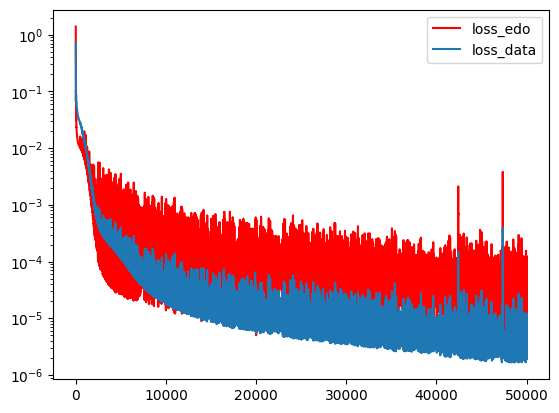

Valor final: Parameter containing:
tensor([0.1582, 0.9849, 0.0170], requires_grad=True)
Valor real: [0.15801272476474815, 0.9863394516628233, 0.016880654207976242]


In [7]:
#plt.plot(LOSS,"k.",label="loss_total")
plt.plot(LOSS1,'r-',label="loss_edo")
plt.plot(LOSS2,label="loss_data")
plt.yscale("log")
plt.legend()
plt.show()
print("Valor final:",X_vector.parametro)
print("Valor real:",dissipation)




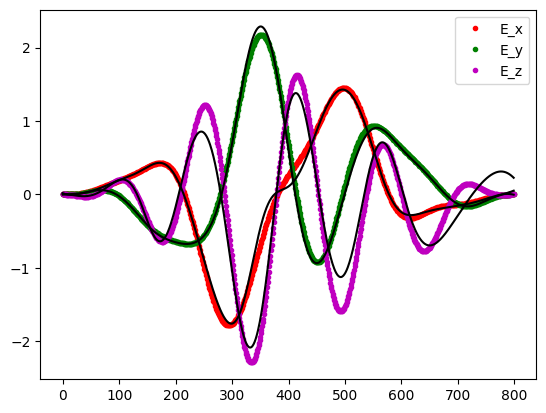

In [8]:
X_=X_vector(time).cpu().detach().numpy()
plt.plot(Fieldx(tlist),"r." ,label=f"E_x")
plt.plot(Fieldy(tlist),"g." ,label=f"E_y")
plt.plot(Fieldz(tlist),"m." ,label=f"E_z")
for i in range(9,12):
    plt.plot(X_[:,i],"k")



plt.legend()
plt.show()

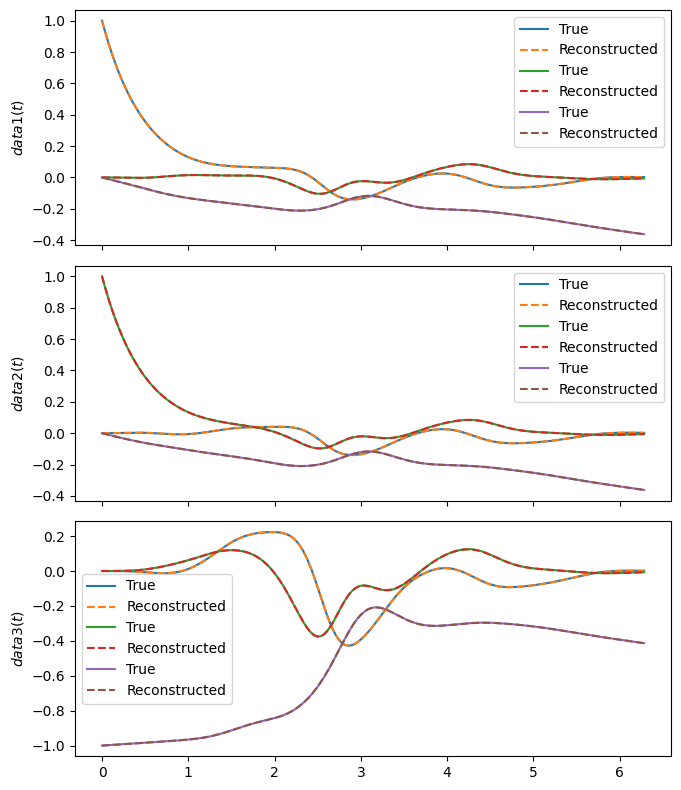

In [9]:
time_np = tlist

fig, ax = plt.subplots(3, 1, figsize=(7, 8), sharex=True)

ax[0].plot(time_np, valor_esperado_data1[:,0:1].cpu().detach().numpy(), label='True')
ax[0].plot(time_np, X_[:, 0], '--', label='Reconstructed')
ax[0].plot(time_np, valor_esperado_data1[:,1:2].cpu().detach().numpy(), label='True')
ax[0].plot(time_np, X_[:, 1], '--', label='Reconstructed')
ax[0].plot(time_np, valor_esperado_data1[:,2].cpu().detach().numpy(), label='True')
ax[0].plot(time_np, X_[:, 2], '--', label='Reconstructed')
ax[0].set_ylabel(r'$data1(t)$')
ax[0].legend()

ax[1].plot(time_np, valor_esperado_data2[:,0:1].cpu().detach().numpy(), label='True')
ax[1].plot(time_np, X_[:, 3], '--', label='Reconstructed')
ax[1].plot(time_np, valor_esperado_data2[:,1:2].cpu().detach().numpy(), label='True')
ax[1].plot(time_np, X_[:, 4], '--', label='Reconstructed')
ax[1].plot(time_np, valor_esperado_data2[:,2].cpu().detach().numpy(), label='True')
ax[1].plot(time_np, X_[:, 5], '--', label='Reconstructed')
ax[1].set_ylabel(r'$data2(t)$')
ax[1].legend()


ax[2].plot(time_np, valor_esperado_data3[:,0:1].cpu().detach().numpy(), label='True')
ax[2].plot(time_np, X_[:, 6], '--', label='Reconstructed')
ax[2].plot(time_np, valor_esperado_data3[:,1:2].cpu().detach().numpy(), label='True')
ax[2].plot(time_np, X_[:, 7], '--', label='Reconstructed')
ax[2].plot(time_np, valor_esperado_data3[:,2].cpu().detach().numpy(), label='True')
ax[2].plot(time_np, X_[:, 8], '--', label='Reconstructed')
ax[2].set_ylabel(r'$data3(t)$')
ax[2].legend()

plt.tight_layout()
plt.show()

In [54]:
def reconstruct_fields_from_data(
    time,
    data1,
    data2,
    data3,
    gamma1,
    gamma2,
    gamma3
):
    """
    Reconstrói JX(t), JY(t), JZ(t) diretamente dos dados
    de três estados iniciais.

    data1, data2, data3:
        arrays com shape (Nt, 3)
        colunas = [Sx, Sy, Sz]
    """

    time = np.asarray(time).flatten()

    data1 = np.asarray(data1)
    data2 = np.asarray(data2)
    data3 = np.asarray(data3)

    Nt = len(time)

    # -----------------------------------------
    # Coeficientes dissipativos
    # -----------------------------------------

    a = -0.5*gamma1 - 2.0*gamma2 - 0.5*gamma3
    c = -gamma1 + gamma3
    d = -gamma1 - gamma3

    # -----------------------------------------
    # Derivadas temporais
    # -----------------------------------------

    ddata1 = np.zeros_like(data1)
    ddata2 = np.zeros_like(data2)
    ddata3 = np.zeros_like(data3)

    for i in range(3):
        ddata1[:, i] = np.gradient(data1[:, i], time)
        ddata2[:, i] = np.gradient(data2[:, i], time)
        ddata3[:, i] = np.gradient(data3[:, i], time)

    # -----------------------------------------
    # Arrays para armazenar JX, JY, JZ
    # -----------------------------------------

    J_rec = np.zeros((Nt, 3))

    condition_number = np.zeros(Nt)
    min_sval = np.zeros(Nt)
    A_list = []
    b_list = []
    coeff_list = []
    res_list = []

    # -----------------------------------------
    # Loop temporal
    # -----------------------------------------

    for k in range(Nt):

        X1, Y1, Z1 = data1[k]
        X2, Y2, Z2 = data2[k]
        X3, Y3, Z3 = data3[k]

        dX1, dY1, dZ1 = ddata1[k]
        dX2, dY2, dZ2 = ddata2[k]
        dX3, dY3, dZ3 = ddata3[k]

        # -------------------------------------
        # Remove a contribuição dissipativa
        # -------------------------------------

        qx1 = dX1 - a*X1
        qy1 = dY1 - a*Y1
        qz1 = dZ1 - c - d*Z1

        qx2 = dX2 - a*X2
        qy2 = dY2 - a*Y2
        qz2 = dZ2 - c - d*Z2

        qx3 = dX3 - a*X3
        qy3 = dY3 - a*Y3
        qz3 = dZ3 - c - d*Z3

        # -------------------------------------
        # Matriz A
        # -------------------------------------

        A = np.array([
            [0.0,  Z1, -Y1],
            [-Z1,  0.0, X1],
            [Y1, -X1,  0.0],

            [0.0,  Z2, -Y2],
            [-Z2, 0.0,  X2],
            [Y2, -X2,  0.0],

            [0.0,  Z3, -Y3],
            [-Z3, 0.0,  X3],
            [Y3, -X3, 0.0]
        ])

        b = np.array([
            qx1, qy1, qz1,
            qx2, qy2, qz2,
            qx3, qy3, qz3
        ])

        # -------------------------------------
        # Reconstrução por mínimos quadrados
        # -------------------------------------
        A_list.append(A)
        b_list.append(b)

        J, residuals, rank, singular_values = np.linalg.lstsq(
            A, b, rcond=None
        )
        res_list.append(residuals)
        J_rec[k, :] = J

        # Compute the coefficient of the solution in the ill-constrained direction (smallest singular value)
        U, s, Vt = np.linalg.svd(A, full_matrices=False)
        
        coeff = U.T @ b
        coeff_list.append(coeff[-1]/s[-1])
        # -------------------------------------
        # Condition number
        # -------------------------------------

        condition_number[k] = np.linalg.cond(A)
        min_sval[k] = np.min(singular_values)

    return J_rec, condition_number, min_sval, A_list, b_list, res_list, coeff_list, ddata1, ddata2, ddata3

In [55]:
gamma1, gamma2, gamma3 = dissipation
tlist=np.linspace(0,tfinal,N4)

J_reconstructed, cond_A_ex, min_sval_ex, A_list_ex, b_list_ex, resid_ex, coeff_ex, ddata1, ddata2, ddata3 = reconstruct_fields_from_data(
    tlist,
    valor_esperado_data1.cpu().detach().numpy(),
    valor_esperado_data2.cpu().detach().numpy(),
    valor_esperado_data3.cpu().detach().numpy(),
    gamma1,
    gamma2,
    gamma3
)

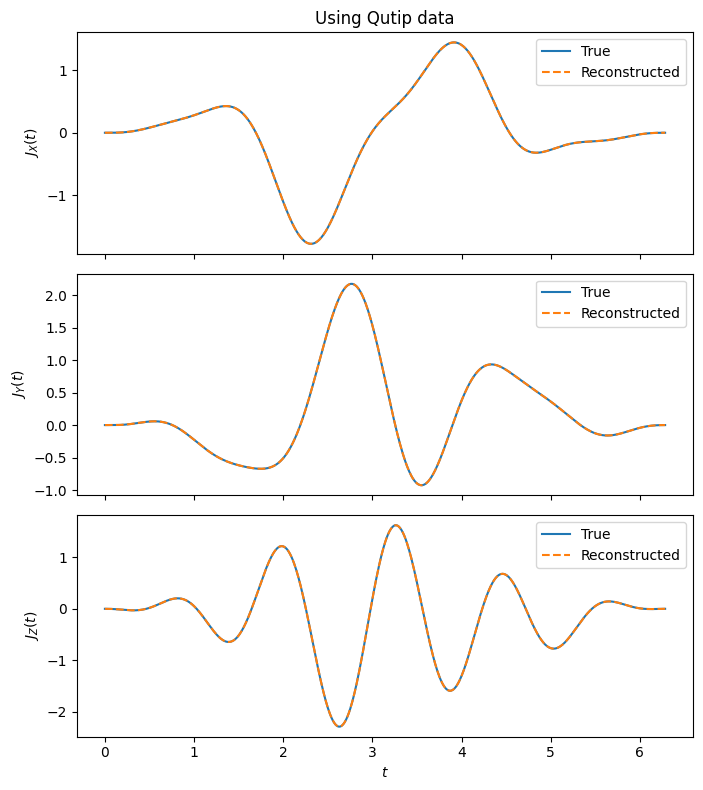

In [41]:
time_np = tlist

fig, ax = plt.subplots(3, 1, figsize=(7, 8), sharex=True)

ax[0].plot(time_np, Fieldx(tlist), label='True')
ax[0].plot(time_np, J_reconstructed[:, 0], '--', label='Reconstructed')
ax[0].set_ylabel(r'$J_X(t)$')
ax[0].set_title("Using Qutip data")
ax[0].legend()


ax[1].plot(time_np, Fieldy(tlist), label='True')
ax[1].plot(time_np, J_reconstructed[:, 1], '--', label='Reconstructed')
ax[1].set_ylabel(r'$J_Y(t)$')
ax[1].legend()

ax[2].plot(time_np, Fieldz(tlist), label='True')
ax[2].plot(time_np, J_reconstructed[:, 2], '--', label='Reconstructed')
ax[2].set_ylabel(r'$J_Z(t)$')
ax[2].set_xlabel(r'$t$')
ax[2].legend()

plt.tight_layout()
plt.show()

Let's test the condition number of the least-squares problem.

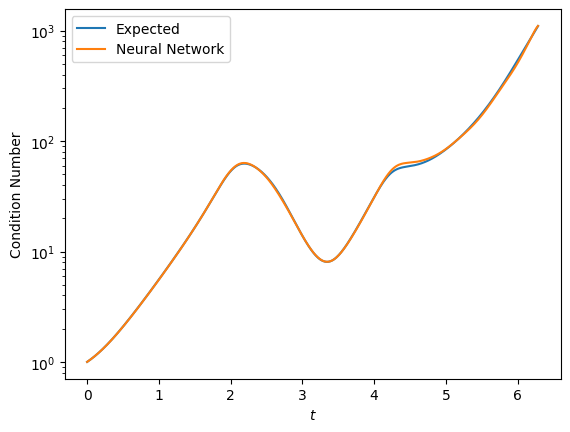

In [ ]:
fig, ax = plt.subplots()

ax.plot(time_np, cond_A_ex, label='Expected')
ax.plot(time_np, cond_A_NN, label='Neural Network')
ax.set_ylabel('Condition Number')
ax.set_xlabel(r'$t$')
ax.set_yscale('log')
ax.legend()
plt.show()

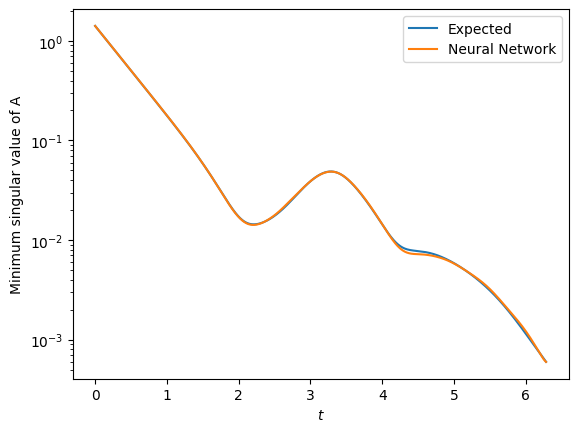

In [30]:
fig, ax = plt.subplots()

ax.plot(time_np, min_sval_ex, label='Expected')
ax.plot(time_np, min_sval_NN, label='Neural Network')
ax.set_ylabel('Minimum singular value of A')
ax.set_xlabel(r'$t$')
ax.set_yscale('log')
ax.legend()
plt.show()

As we can see, the condition number becomes really large at long evolution times, and it is due to a small singular value of the problem matrix.

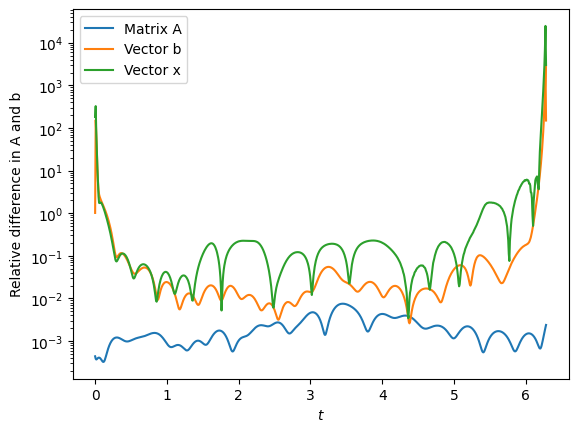

In [45]:
fig, ax = plt.subplots()

Adiffs = [np.linalg.norm(A_list_ex[i] - A_list_NN[i]) / np.linalg.norm(A_list_ex[i]) for i in range(len(A_list_ex))]
bdiffs = [np.linalg.norm(b_list_ex[i] - b_list_NN[i]) / np.linalg.norm(b_list_ex[i]) for i in range(len(b_list_ex))]
xdiffs = [np.linalg.norm(J_reconstructed_NN[i, :] - J_reconstructed[i, :]) / np.linalg.norm(J_reconstructed[i, :]) for i in range(len(b_list_ex))]
ax.plot(time_np, Adiffs, label='Matrix A')
ax.plot(time_np, bdiffs, label='Vector b')
ax.plot(time_np, xdiffs, label='Vector x')
ax.set_ylabel('Relative difference in A and b')
ax.set_xlabel(r'$t$')
ax.set_yscale('log')
ax.legend()
plt.show()

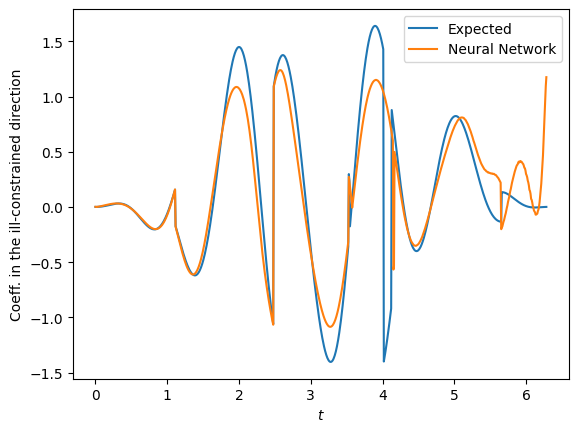

In [58]:
fig, ax = plt.subplots()

ax.plot(time_np, coeff_ex, label='Expected')
ax.plot(time_np, coeff_NN, label='Neural Network')
ax.set_ylabel('Coeff. in the ill-constrained direction')
ax.set_xlabel(r'$t$')
#ax.set_yscale('log')
ax.legend()
plt.show()

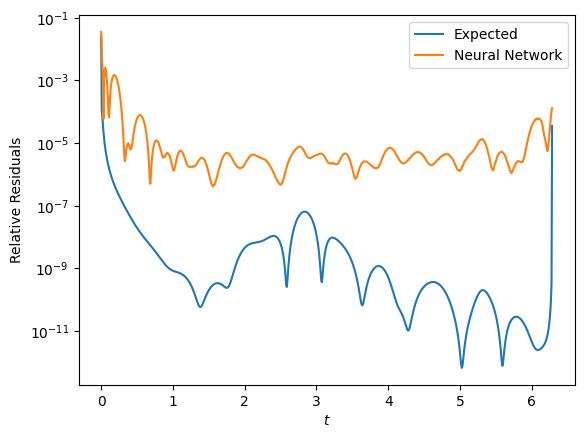

In [61]:
fig, ax = plt.subplots()

rel_resid_ex = [resid_ex[i] / np.linalg.norm(b_list_ex[i]) for i in range(len(resid_ex))]
rel_resid_NN = [resid_NN[i] / np.linalg.norm(b_list_NN[i]) for i in range(len(resid_NN))]

ax.plot(time_np, rel_resid_ex, label='Expected')
ax.plot(time_np, rel_resid_NN, label='Neural Network')
ax.set_ylabel('Relative Residuals')
ax.set_xlabel(r'$t$')
ax.set_yscale('log')
ax.legend()
plt.show()

In [56]:
gamma1, gamma2, gamma3 = X_vector.parametro.cpu().detach().numpy()
X_=X_vector(time).cpu().detach().numpy()
J_reconstructed_NN,cond_A_NN,min_sval_NN,A_list_NN,b_list_NN,resid_NN,coeff_NN,ddata1,ddata2,ddata3 = reconstruct_fields_from_data(
    tlist,
    X_[:,0:3],
    X_[:,3:6],
    X_[:,6:9],
    gamma1,
    gamma2,
    gamma3
)

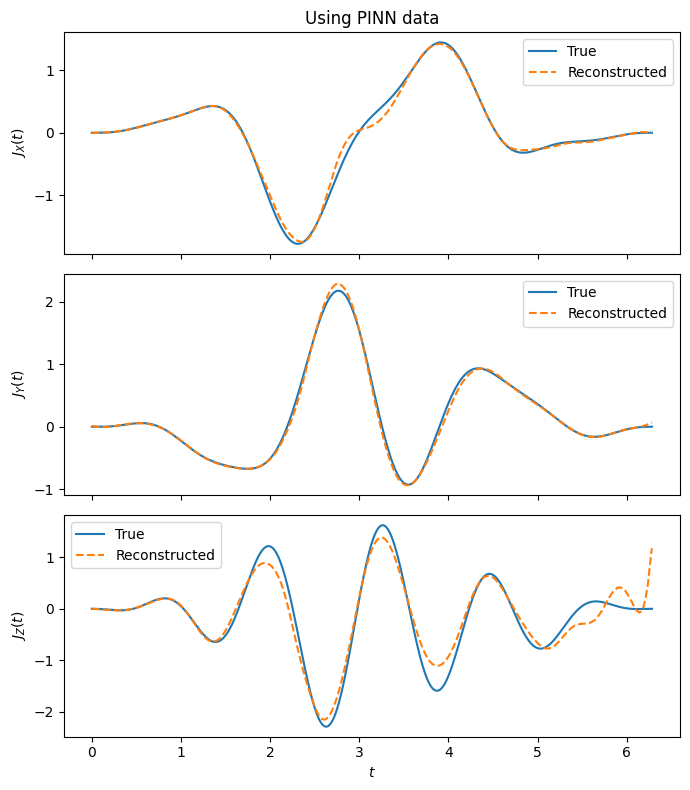

In [43]:
time_np = tlist

fig, ax = plt.subplots(3, 1, figsize=(7, 8), sharex=True)

ax[0].plot(time_np, Fieldx(tlist), label='True')
ax[0].plot(time_np, J_reconstructed_NN[:, 0], '--', label='Reconstructed')
ax[0].set_ylabel(r'$J_X(t)$')
ax[0].set_title("Using PINN data")
ax[0].legend()

ax[1].plot(time_np, Fieldy(tlist), label='True')
ax[1].plot(time_np, J_reconstructed_NN[:, 1], '--', label='Reconstructed')
ax[1].set_ylabel(r'$J_Y(t)$')
ax[1].legend()

ax[2].plot(time_np, Fieldz(tlist), label='True')
ax[2].plot(time_np, J_reconstructed_NN[:, 2], '--', label='Reconstructed')
ax[2].set_ylabel(r'$J_Z(t)$')
ax[2].set_xlabel(r'$t$')
ax[2].legend()

plt.tight_layout()
plt.show()

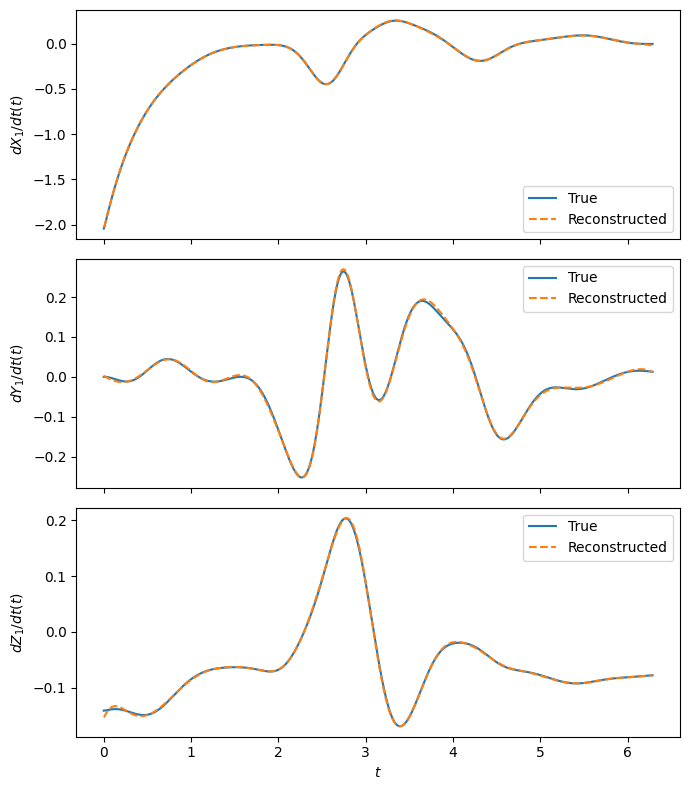

In [18]:
time_np = tlist

fig, ax = plt.subplots(3, 1, figsize=(7, 8), sharex=True)

ax[0].plot(time_np, ddata1[:,0], label='True')
ax[0].plot(time_np, dX1[:, 0], '--', label='Reconstructed')
ax[0].set_ylabel(r'$dX_1/dt(t)$')
ax[0].legend()

ax[1].plot(time_np, ddata1[:,1], label='True')
ax[1].plot(time_np, dX1[:, 1], '--', label='Reconstructed')
ax[1].set_ylabel(r'$dY_1/dt(t)$')
ax[1].legend()

ax[2].plot(time_np, ddata1[:,2], label='True')
ax[2].plot(time_np, dX1[:, 2], '--', label='Reconstructed')
ax[2].set_ylabel(r'$dZ_1/dt(t)$')
ax[2].set_xlabel(r'$t$')
ax[2].legend()

plt.tight_layout()
plt.show()

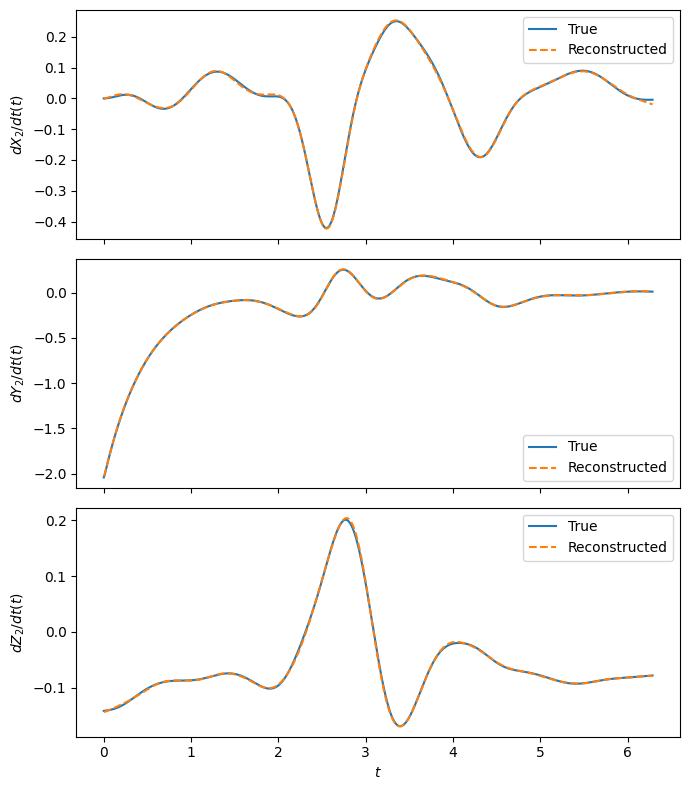

In [19]:
time_np = tlist

fig, ax = plt.subplots(3, 1, figsize=(7, 8), sharex=True)

ax[0].plot(time_np, ddata2[:,0], label='True')
ax[0].plot(time_np, dX2[:, 0], '--', label='Reconstructed')
ax[0].set_ylabel(r'$dX_2/dt(t)$')
ax[0].legend()

ax[1].plot(time_np, ddata2[:,1], label='True')
ax[1].plot(time_np, dX2[:, 1], '--', label='Reconstructed')
ax[1].set_ylabel(r'$dY_2/dt(t)$')
ax[1].legend()

ax[2].plot(time_np, ddata2[:,2], label='True')
ax[2].plot(time_np, dX2[:, 2], '--', label='Reconstructed')
ax[2].set_ylabel(r'$dZ_2/dt(t)$')
ax[2].set_xlabel(r'$t$')
ax[2].legend()

plt.tight_layout()
plt.show()

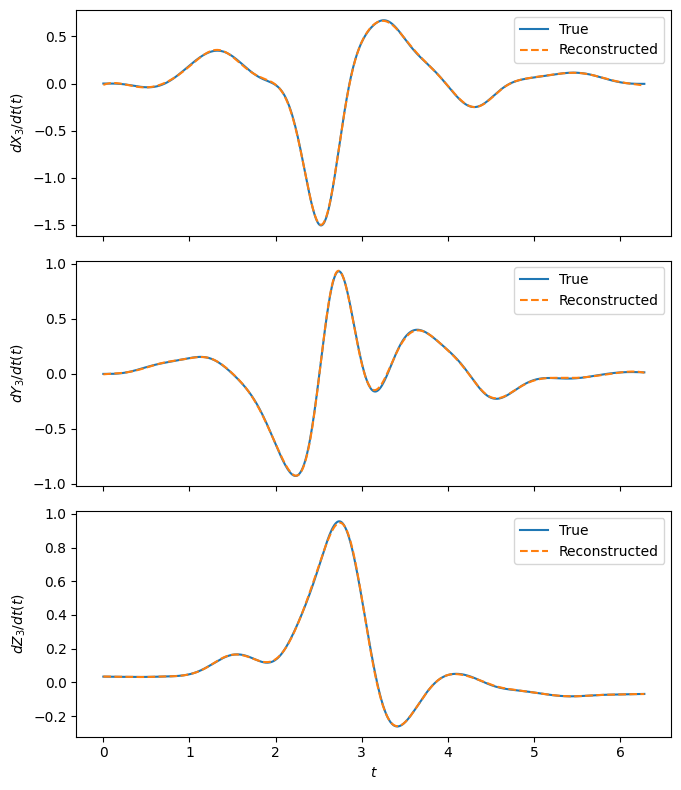

In [20]:
time_np = tlist

fig, ax = plt.subplots(3, 1, figsize=(7, 8), sharex=True)

ax[0].plot(time_np, ddata3[:,0], label='True')
ax[0].plot(time_np, dX3[:, 0], '--', label='Reconstructed')
ax[0].set_ylabel(r'$dX_3/dt(t)$')
ax[0].legend()

ax[1].plot(time_np, ddata3[:,1], label='True')
ax[1].plot(time_np, dX3[:, 1], '--', label='Reconstructed')
ax[1].set_ylabel(r'$dY_3/dt(t)$')
ax[1].legend()

ax[2].plot(time_np, ddata3[:,2], label='True')
ax[2].plot(time_np, dX3[:, 2], '--', label='Reconstructed')
ax[2].set_ylabel(r'$dZ_3/dt(t)$')
ax[2].set_xlabel(r'$t$')
ax[2].legend()

plt.tight_layout()
plt.show()

In [21]:
def reconstruct_fields(
    data1,
    data2,
    data3,
    derivatives1,
    derivatives2,
    derivatives3,
    gamma1,
    gamma2,
    gamma3,
    lambda_smooth=0.1
):
    """
    Reconstrói JX(t), JY(t) e JZ(t) a partir de três
    trajetórias de Bloch e suas derivadas temporais.

    A reconstrução é feita globalmente em todo o intervalo de tempo,
    com uma regularização de suavidade baseada na segunda diferença
    temporal dos campos.

    lambda_smooth = 0:
        reconstrução original, ponto a ponto.

    lambda_smooth > 0:
        impõe suavidade temporal aos campos.

    Retorna
    -------
    J_reconstructed : array (Nt, 3)
        Colunas [JX, JY, JZ]

    condition_number : array (Nt,)
        Número de condicionamento da matriz A(t) em cada instante.
    """

    Nt = data1.shape[0]

    # ==========================================================
    # Coeficientes da parte dissipativa
    # ==========================================================

    a = -0.5 * gamma1 - 2.0 * gamma2 - 0.5 * gamma3

    c = -gamma1 + gamma3

    d = -gamma1 - gamma3


    # ==========================================================
    # Matrizes do problema global
    #
    # Em cada instante:
    #
    #       A_k J_k = b_k
    #
    # Queremos determinar todos os J_k simultaneamente.
    # ==========================================================

    A_global = np.zeros((9 * Nt, 3 * Nt))

    b_global = np.zeros(9 * Nt)


    # ==========================================================
    # Construção de A_global e b_global
    # ==========================================================

    condition_number = np.zeros(Nt)

    for k in range(Nt):

        # ------------------------------------------------------
        # Estado 1
        # ------------------------------------------------------

        X1, Y1, Z1 = data1[k]

        dX1, dY1, dZ1 = derivatives1[k]


        # ------------------------------------------------------
        # Estado 2
        # ------------------------------------------------------

        X2, Y2, Z2 = data2[k]

        dX2, dY2, dZ2 = derivatives2[k]


        # ------------------------------------------------------
        # Estado 3
        # ------------------------------------------------------

        X3, Y3, Z3 = data3[k]

        dX3, dY3, dZ3 = derivatives3[k]


        # ------------------------------------------------------
        # Retirando a contribuição dissipativa
        # ------------------------------------------------------

        qx1 = dX1 - a * X1
        qy1 = dY1 - a * Y1
        qz1 = dZ1 - c - d * Z1

        qx2 = dX2 - a * X2
        qy2 = dY2 - a * Y2
        qz2 = dZ2 - c - d * Z2

        qx3 = dX3 - a * X3
        qy3 = dY3 - a * Y3
        qz3 = dZ3 - c - d * Z3


        # ------------------------------------------------------
        # Matriz A_k
        #
        # q = A J
        #
        # J = [JX, JY, JZ]
        # ------------------------------------------------------

        A = np.array([

            # Estado 1
            [ 0.0,  Z1, -Y1],
            [-Z1,  0.0,  X1],
            [ Y1, -X1,  0.0],

            # Estado 2
            [ 0.0,  Z2, -Y2],
            [-Z2,  0.0,  X2],
            [ Y2, -X2,  0.0],

            # Estado 3
            [ 0.0,  Z3, -Y3],
            [-Z3,  0.0,  X3],
            [ Y3, -X3,  0.0]
        ])


        b = np.array([
            qx1,
            qy1,
            qz1,

            qx2,
            qy2,
            qz2,

            qx3,
            qy3,
            qz3
        ])


        # ------------------------------------------------------
        # Coloca A_k no bloco correspondente
        # ------------------------------------------------------

        row_start = 9 * k
        row_end   = 9 * (k + 1)

        col_start = 3 * k
        col_end   = 3 * (k + 1)

        A_global[row_start:row_end, col_start:col_end] = A

        b_global[row_start:row_end] = b


        # ------------------------------------------------------
        # Condicionamento local
        # ------------------------------------------------------

        condition_number[k] = np.linalg.cond(A)


    # ==========================================================
    # Reconstrução sem regularização
    #
    # lambda_smooth = 0
    # ==========================================================

    if lambda_smooth == 0.0:

        J_global, _, _, _ = np.linalg.lstsq(
            A_global,
            b_global,
            rcond=None
        )


    # ==========================================================
    # Reconstrução com suavidade temporal
    #
    # Minimiza:
    #
    # ||A_global J - b_global||^2
    #
    # + lambda_smooth ||D2 J||^2
    #
    # onde D2 representa:
    #
    # J[k+1] - 2 J[k] + J[k-1]
    # ==========================================================

    else:

        # Número de variáveis
        n_variables = 3 * Nt

        # Número de pontos de segunda diferença
        n_second_diff = Nt - 2

        # Cada ponto temporal possui 3 campos
        D2 = np.zeros(
            (3 * n_second_diff, n_variables)
        )

        for k in range(1, Nt - 1):

            row = 3 * (k - 1)

            # J[k-1]
            D2[row:row+3, 3*(k-1):3*k] = np.eye(3)

            # -2 J[k]
            D2[row:row+3, 3*k:3*(k+1)] = -2.0 * np.eye(3)

            # J[k+1]
            D2[row:row+3, 3*(k+1):3*(k+2)] = np.eye(3)


        # ------------------------------------------------------
        # Sistema aumentado:
        #
        # [ A_global ] J = [ b_global ]
        # [ sqrt(lam)D2]    [    0     ]
        # ------------------------------------------------------

        A_augmented = np.vstack([
            A_global,
            np.sqrt(lambda_smooth) * D2
        ])

        b_augmented = np.concatenate([
            b_global,
            np.zeros(3 * n_second_diff)
        ])


        # ------------------------------------------------------
        # Solução global regularizada
        # ------------------------------------------------------

        J_global, _, _, _ = np.linalg.lstsq(
            A_augmented,
            b_augmented,
            rcond=None
        )


    # ==========================================================
    # Reorganiza:
    #
    # J_global =
    # [JX(t0), JY(t0), JZ(t0),
    #  JX(t1), JY(t1), JZ(t1), ...]
    #
    # para:
    #
    # J_reconstructed[:,0] = JX
    # J_reconstructed[:,1] = JY
    # J_reconstructed[:,2] = JZ
    # ==========================================================

    J_reconstructed = J_global.reshape(Nt, 3)


    return J_reconstructed, condition_number

In [22]:
gamma1, gamma2, gamma3 = X_vector.parametro.cpu().detach().numpy()
X_=X_vector(time).cpu().detach().numpy()
J_recon,cond_A = reconstruct_fields(
    X_[:,0:3],
    X_[:,3:6],
    X_[:,6:9],
    dX1,
    dX2,
    dX3,
    gamma1,
    gamma2,
    gamma3,
    lambda_smooth=0.01
)

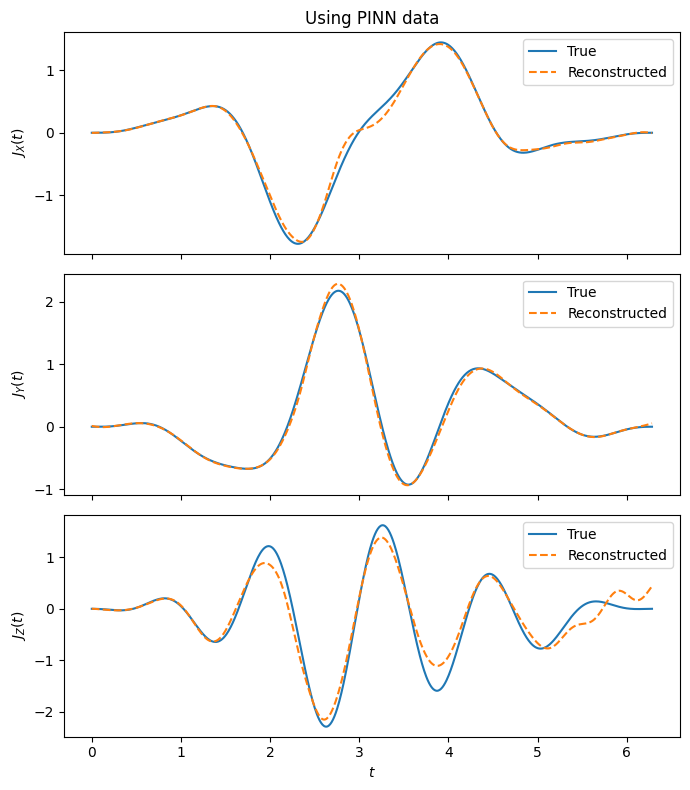

In [23]:
time_np = tlist

fig, ax = plt.subplots(3, 1, figsize=(7, 8), sharex=True)

ax[0].plot(time_np, Fieldx(tlist), label='True')
ax[0].plot(time_np, J_recon[:, 0], '--', label='Reconstructed')
ax[0].set_ylabel(r'$J_X(t)$')
ax[0].set_title("Using PINN data")
ax[0].legend()

ax[1].plot(time_np, Fieldy(tlist), label='True')
ax[1].plot(time_np, J_recon[:, 1], '--', label='Reconstructed')
ax[1].set_ylabel(r'$J_Y(t)$')
ax[1].legend()

ax[2].plot(time_np, Fieldz(tlist), label='True')
ax[2].plot(time_np, J_recon[:, 2], '--', label='Reconstructed')
ax[2].set_ylabel(r'$J_Z(t)$')
ax[2].set_xlabel(r'$t$')
ax[2].legend()

plt.tight_layout()
plt.show()